# 63 · Attention, derived and verified: QKV, scaling, masks, positional encodings

In [1]:
import math, numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt

def attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    w = scores.softmax(-1)
    return w @ v, w

def causal_mask(T):
    return torch.tril(torch.ones(T, T, dtype=torch.bool))

def sinusoidal(T, d):
    pos = torch.arange(T)[:, None]; i = torch.arange(0, d, 2)[None]
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(pos / 10000 ** (i / d)); pe[:, 1::2] = torch.cos(pos / 10000 ** (i / d))
    return pe

In [2]:
torch.manual_seed(0)
B, H, T, d = 2, 4, 6, 16
q, k, v = torch.randn(B, H, T, d), torch.randn(B, H, T, d), torch.randn(B, H, T, d)
ours, w = attention(q, k, v, causal_mask(T))
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
print("matches torch scaled_dot_product_attention:", torch.allclose(ours, ref, atol=1e-6))
print("each row of the attention matrix sums to 1:", torch.allclose(w.sum(-1), torch.ones(B, H, T)))

matches torch scaled_dot_product_attention: True
each row of the attention matrix sums to 1: True


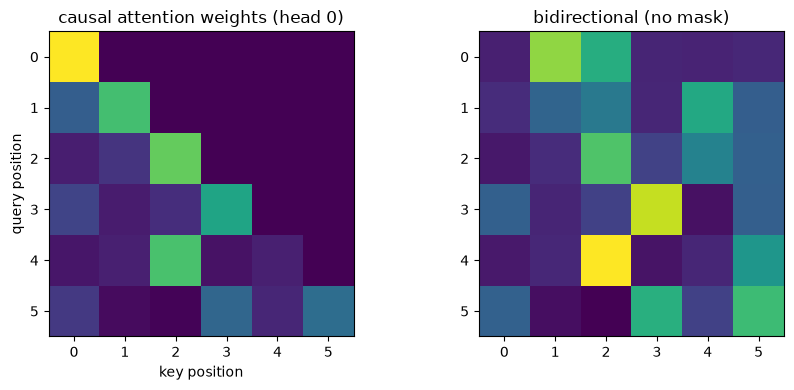

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(w[0, 0].detach(), cmap="viridis"); ax[0].set_title("causal attention weights (head 0)"); ax[0].set_xlabel("key position"); ax[0].set_ylabel("query position")
_, wf = attention(q, k, v)
ax[1].imshow(wf[0, 0].detach(), cmap="viridis"); ax[1].set_title("bidirectional (no mask)"); plt.tight_layout(); plt.show()

In [4]:
for dim in [4, 64, 1024]:
    qq, kk = torch.randn(10000, dim), torch.randn(10000, dim)
    raw = (qq * kk).sum(-1)
    print(f"d={dim:5d}: std of q·k = {raw.std():7.2f}   after /sqrt(d): {(raw / math.sqrt(dim)).std():.2f}")
s = torch.randn(1, 8) * 30
print("softmax of unscaled large logits is nearly one-hot:", s.softmax(-1).max().item().__round__(4), "-> vanishing gradients")

d=    4: std of q·k =    2.00   after /sqrt(d): 1.00
d=   64: std of q·k =    8.01   after /sqrt(d): 1.00
d= 1024: std of q·k =   32.09   after /sqrt(d): 1.00
softmax of unscaled large logits is nearly one-hot: 1.0 -> vanishing gradients


self-attention without positions is permutation-equivariant:

 True


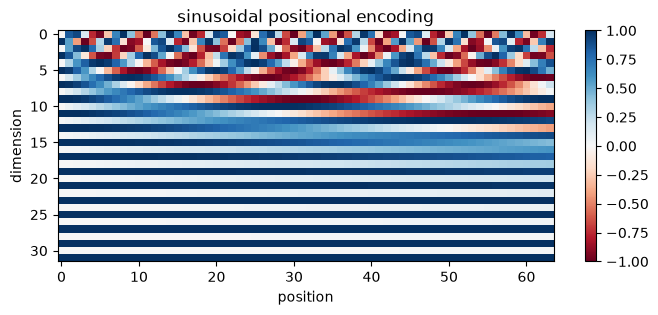

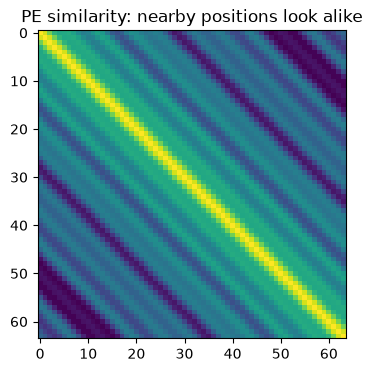

In [5]:
x = torch.randn(1, 5, 8)
perm = torch.tensor([4, 2, 0, 1, 3])
out, _ = attention(x, x, x)
out_p, _ = attention(x[:, perm], x[:, perm], x[:, perm])
print("self-attention without positions is permutation-equivariant:", torch.allclose(out[:, perm], out_p, atol=1e-6))
pe = sinusoidal(64, 32)
plt.figure(figsize=(8, 3)); plt.imshow(pe.T, aspect="auto", cmap="RdBu"); plt.xlabel("position"); plt.ylabel("dimension")
plt.title("sinusoidal positional encoding"); plt.colorbar(); plt.show()
sim = pe @ pe.T
plt.figure(figsize=(4, 4)); plt.imshow(sim, cmap="viridis"); plt.title("PE similarity: nearby positions look alike"); plt.show()